# Usage examples

Each section trains one seed of DAGMA (least-squares loss) on one experiment and plots SHD against the amount of domain knowledge:

1. **CausalMan, forbidden edges** (`tier_mask`)
2. **Sachs, given edges** (`given_edges`, with the no-knowledge point from `tier_mask`)
3. **CausalMan, given colliders** (`given_colliders`)
4. **causalAssembly, forbidden edges** from the station order and from TierSort
5. **Drawing graphs**: a benchmark's true graph and one run's estimate

Before running this notebook, run `uv sync` and build the datasets with `python -m benchmarks` (see the README). Training uses the GPU if it is available.

In [5]:
from analysis import lines
from train import run

# Learner (and config-set) names are in src/train/config.toml; "dagma_adam" is
# DAGMA with the least-squares loss.
LEARNERS = ["dagma_adam"]
JOBS = 3  # runs trained at a time, each in its own process

# Which runs a plot uses: that learner, seed 0, z-scored data.
PICK = {"base": "dagma_adam", "loss_fn": "l2", "seed": 0, "normalization": "zscore"}

## Example 1. CausalMan with forbidden edges

First, let's try running on the CausalMan dataset. The domain knowledge we will use is forbidding edges from later 'tiers' to earlier 'tiers', corresponding, which could correspond to the knowledge that later stations cannot affect earlier ones.

`tier_mask` forbids edges that point from a later tier to an earlier one, keeping a growing fraction of the forbidden set (`mask_fraction`, x axis). The grid is the learners × the experiment's axes from the config × the benchmark's noise levels (CausalMan: 10% injected noise) x the seeds.

In [6]:
grid = run.build_grid("tier_mask", "causalman", configs=LEARNERS, seeds=[0])
print(len(grid), "runs ->", grid[0].exp_dir)
run.train(grid, jobs=JOBS)

9 runs -> data\results\causalman\tier_mask
9 runs: 0 done, 0 failed, 9 pending


  [1/9] started 14f7f0a5e5b55f24: dagma_adam/l2 mask_fraction=0.0 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  [2/9] started 872324687c1c733a: dagma_adam/l2 mask_fraction=0.25 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  [3/9] started dea4e19ccfa2b477: dagma_adam/l2 mask_fraction=0.5 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  dea4e19ccfa2b477 done in 258s
  [4/9] started 51ee952d28cd4811: dagma_adam/l2 mask_fraction=0.75 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  14f7f0a5e5b55f24 done in 277s
  [5/9] started da0b8ed9e265ceb7: dagma_adam/l2 mask_fraction=0.8 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  872324687c1c733a done in 319s
  [6/9] started c3684568170220c1: dagma_adam/l2 mask_fraction=0.85 tier_source=reference noise=0.1 n_samples=None dk_seed=0 seed=0
  da0b8ed9e265ceb7 done in 245s
  [7/9] started dfe5a264a9c83e9f: dagma_adam/l2 mask_fraction=0.9 tier_source=reference n

### Analyze and plot

**Where the runs go.** Each run is saved under
`data/results/<benchmark>/<experiment>/runs/<run_id>/` (here
`data/results/causalman/tier_mask/runs/`), in a folder of its own:

- `run.json`: the run's inputs (learner, axis values, noise, seeds, dataset
  fingerprint, ...), its status (`ok` / `failed` and the error) and training time;
- `metrics.csv`: every metric at each `w_threshold`;
- `graph.npz`: the learned weights `W` (unthresholded), variable names, true graph
  and given edges;
- `log.txt`: the training output.

The run ID is a hash of all the inputs, so re-running a cell skips the runs that
are already there and only trains what is missing; a run with any input changed
gets a new folder. Reading an experiment caches its runs in `<experiment>/all_results.csv`.

`lines.table` reduces the runs to one point per (learner, x): at each point the
`w_threshold` with the best mean SHD is used, and the table records it. A seed
whose estimate is cyclic at that threshold is scored at its own smallest acyclic
threshold (`cyclic="fill"`; the default `"drop"` leaves it out).

data\results\causalman\tier_mask: 9 runs -> all_results.csv


,label,x,base,loss_fn,y,lo,hi,n,w_threshold
0,dagma_adam/l2,0.00,dagma_adam,l2,28.0,28.0,28.0,1,0.2
1,dagma_adam/l2,0.25,dagma_adam,l2,29.0,29.0,29.0,1,0.3
2,dagma_adam/l2,0.50,dagma_adam,l2,30.0,30.0,30.0,1,0.3
3,dagma_adam/l2,0.75,dagma_adam,l2,31.0,31.0,31.0,1,0.3
4,dagma_adam/l2,0.80,dagma_adam,l2,27.0,27.0,27.0,1,0.6


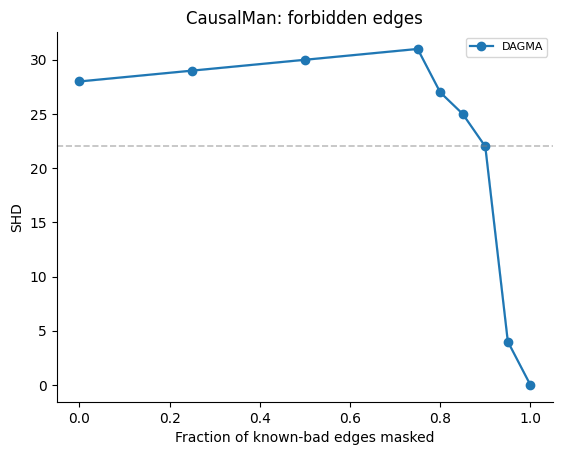

In [7]:
cm = lines.table(grid[0].exp_dir, x="mask_fraction", where={**PICK, "noise": 0.1}, cyclic="fill")
lines.draw(cm, title="CausalMan: forbidden edges", reference=22)  # dashed: the true edge count
cm.head()

## Example 2. Sachs with given edges

Now, let's run on the Sachs dataset.

`given_edges` hands the learner a fraction of the true edges (`frac_given`) and
encourages them with a hinge on their magnitude, over a grid of hinge margins and
weights. To keep this quick, we will train one hinge setting in this example. Without the filter the
whole grid is trained and `best_over` picks the best setting per point. The
no-knowledge point (x = 0) is `tier_mask` at mask fraction 0, used as the
`baseline`.

In [8]:
grid = [
    r
    for r in run.build_grid("given_edges", "sachs", configs=LEARNERS, seeds=[0])
    if (r.identity["given_hinge_margin"], r.identity["given_hinge_weight"]) == (0.1, 0.1)
]
base = [
    r
    for r in run.build_grid("tier_mask", "sachs", configs=LEARNERS, seeds=[0])
    if r.identity["mask_fraction"] == 0
]
run.train(grid + base, jobs=JOBS)

5 runs: 0 done, 0 failed, 5 pending
  [1/5] started 629e6d2a0737c012: dagma_adam/l2 frac_given=0.1 given_mode=hinge given_hinge_margin=0.1 given_hinge_weight=0.1 lambda1_given=None mask_reverse=True noise=None n_samples=None dk_seed=0 seed=0
  [2/5] started f0ecf5055cff2537: dagma_adam/l2 frac_given=0.25 given_mode=hinge given_hinge_margin=0.1 given_hinge_weight=0.1 lambda1_given=None mask_reverse=True noise=None n_samples=None dk_seed=0 seed=0
  [3/5] started 3ce0bc1eca3bc326: dagma_adam/l2 frac_given=0.5 given_mode=hinge given_hinge_margin=0.1 given_hinge_weight=0.1 lambda1_given=None mask_reverse=True noise=None n_samples=None dk_seed=0 seed=0
  3ce0bc1eca3bc326 done in 165s
  [4/5] started e20575d134bdbf1d: dagma_adam/l2 frac_given=0.75 given_mode=hinge given_hinge_margin=0.1 given_hinge_weight=0.1 lambda1_given=None mask_reverse=True noise=None n_samples=None dk_seed=0 seed=0
  629e6d2a0737c012 done in 172s
  [5/5] started 4109d8e5a6b4473b: dagma_adam/l2 mask_fraction=0.0 tier_sou

data\results\sachs\tier_mask: 1 runs -> all_results.csv
data\results\sachs\given_edges: 4 runs -> all_results.csv


<Axes: title={'center': 'Sachs: given edges'}, xlabel='Fraction of true edges given', ylabel='SHD'>

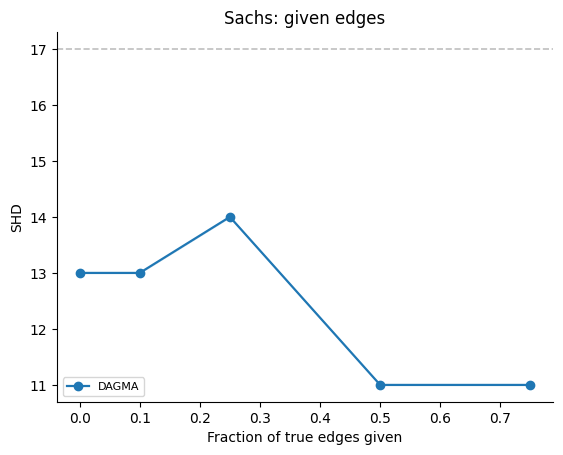

In [9]:
no_knowledge = lines.table(base[0].exp_dir, x="mask_fraction", where={**PICK, "noise": None})
ge = lines.table(
    grid[0].exp_dir,
    x="frac_given",
    baseline=no_knowledge,
    where={
        **PICK,
        "noise": None,
        "given_mode": ["hinge", None],
        "mask_reverse": [True, None],
    },  # None: unset, as in the x = 0 runs
    best_over=["w_threshold", "given_hinge_margin", "given_hinge_weight"],
)
lines.draw(ge, title="Sachs: given edges", reference=17)

## Example 3. CausalMan with given colliders

`given_colliders` gives both incoming edges of a fraction of the graph's
(unshielded) colliders, `a -> c <- b` (`frac_colliders`, x axis; CausalMan has
10), encouraged with a negative L1 weight (`given_mode="neg_l1"`). Its grid
includes the no-knowledge point (fraction 0) itself. Five runs, a few GPU-minutes each.

In [10]:
grid = run.build_grid("given_colliders", "causalman", configs=LEARNERS, seeds=[0])
run.train(grid, jobs=JOBS)

5 runs: 0 done, 0 failed, 5 pending
  [1/5] started 96c05827a962a4f0: dagma_adam/l2 frac_colliders=0.0 given_mode=neg_l1 lambda1_given=None mask_reverse=True noise=0.1 n_samples=None dk_seed=0 seed=0
  [2/5] started 335a16e76b2e1db0: dagma_adam/l2 frac_colliders=0.25 given_mode=neg_l1 lambda1_given=None mask_reverse=True noise=0.1 n_samples=None dk_seed=0 seed=0
  [3/5] started b05e9e13011f1275: dagma_adam/l2 frac_colliders=0.5 given_mode=neg_l1 lambda1_given=None mask_reverse=True noise=0.1 n_samples=None dk_seed=0 seed=0
  96c05827a962a4f0 done in 301s
  [4/5] started ef46bbdecd9f3b65: dagma_adam/l2 frac_colliders=0.75 given_mode=neg_l1 lambda1_given=None mask_reverse=True noise=0.1 n_samples=None dk_seed=0 seed=0
  335a16e76b2e1db0 done in 323s
  [5/5] started a1f131eaf3c83783: dagma_adam/l2 frac_colliders=1.0 given_mode=neg_l1 lambda1_given=None mask_reverse=True noise=0.1 n_samples=None dk_seed=0 seed=0
  b05e9e13011f1275 done in 324s
  a1f131eaf3c83783 done in 237s
  ef46bbdecd9f

data\results\causalman\given_colliders: 5 runs -> all_results.csv


<Axes: title={'center': 'CausalMan: given colliders'}, xlabel='Fraction of colliders given', ylabel='SHD'>

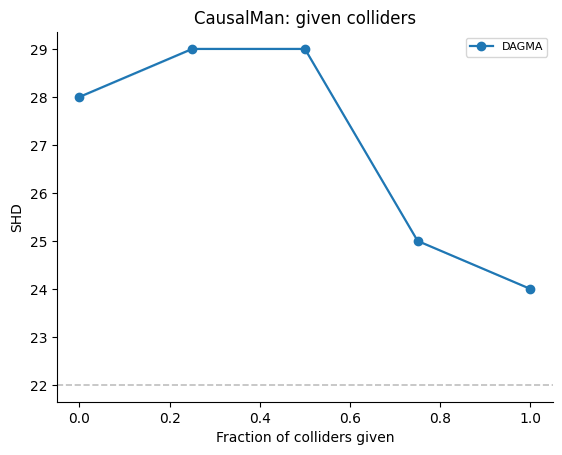

In [11]:
gc = lines.table(
    grid[0].exp_dir,
    x="frac_colliders",
    where={**PICK, "noise": 0.1, "given_mode": "neg_l1", "lambda1_given": None},
)
lines.draw(gc, title="CausalMan: given colliders", reference=22)

## Example 4. causalAssembly with station tiers vs with TierSort

On causalAssembly, `tier_mask` runs with two tier sources: the production
line's station order and TierSort (the true DAG's topological generations). Both
are a `tier_source` axis in the same experiment directory. These runs take a few
GPU-minutes each, so this trains five of the nine mask fractions.

In [12]:
grid = [
    r
    for r in run.build_grid("tier_mask", "causalassembly", configs=LEARNERS, seeds=[0])
    if r.identity["mask_fraction"] in (0.0, 0.5, 0.75, 0.9, 1.0)
]
print(len(grid), "runs")
run.train(grid, jobs=JOBS)

10 runs
10 runs: 0 done, 0 failed, 10 pending
  [1/10] started b9c45523ae62f717: dagma_adam/l2 mask_fraction=0.0 tier_source=station noise=None n_samples=None dk_seed=0 seed=0
  [2/10] started aa785abda228605d: dagma_adam/l2 mask_fraction=0.0 tier_source=dag noise=None n_samples=None dk_seed=0 seed=0
  [3/10] started e0626dc64f64d0be: dagma_adam/l2 mask_fraction=0.5 tier_source=station noise=None n_samples=None dk_seed=0 seed=0
  aa785abda228605d done in 639s
  [4/10] started 4c578a045cafcfef: dagma_adam/l2 mask_fraction=0.5 tier_source=dag noise=None n_samples=None dk_seed=0 seed=0
  b9c45523ae62f717 done in 639s
  [5/10] started b52621973100d9d2: dagma_adam/l2 mask_fraction=0.75 tier_source=station noise=None n_samples=None dk_seed=0 seed=0
  e0626dc64f64d0be done in 723s
  [6/10] started 2112abf5e80df9e6: dagma_adam/l2 mask_fraction=0.75 tier_source=dag noise=None n_samples=None dk_seed=0 seed=0
  4c578a045cafcfef done in 682s
  [7/10] started 510fbc9b4ddfc4d6: dagma_adam/l2 mask_fr

data\results\causalassembly\tier_mask: 10 runs -> all_results.csv


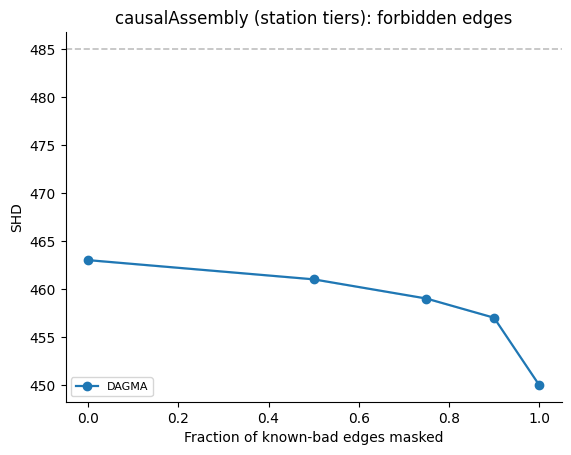

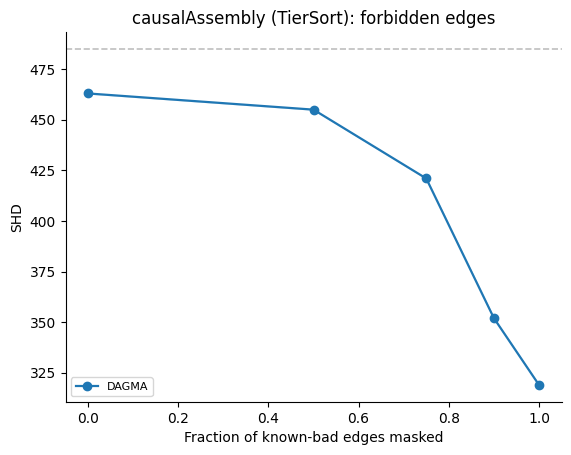

In [13]:
for source, name in [("station", "station tiers"), ("dag", "TierSort")]:
    ca = lines.table(
        grid[0].exp_dir,
        x="mask_fraction",
        where={**PICK, "noise": None, "tier_source": source},
        cyclic="fill",
    )
    lines.draw(ca, title=f"causalAssembly ({name}): forbidden edges", reference=485)

Both sources in one plot instead: add `"tier_source"` to the line labels,
`lines.table(..., where=PICK | {"noise": None}, labels=["base", "loss_fn", "tier_source"])`.

## 5. Drawing graphs

`visualize.graph` draws interactive graphs of a benchmark's true graph, or of a run's estimate of it (true
positives grey, false positives red, missed edges dashed orange). Each is an
HTML page (here `data/datasets/sachs_graph.html`, and `graph_t<threshold>.html`
in the run's folder) that the cells below write and print the path of: open it in a web browser.
From a shell:
`python -m visualize.graph benchmark sachs`, `python -m visualize.graph run
<exp_dir> <run_id>`. CausalMan graphs use CausalMan's provided reference layout, graphs of other datasets are drawn 
in topological layers.

In [ ]:
from visualize import graph

path = graph.render_benchmark("sachs")

In [ ]:
# The Sachs run from section 2 with half the true edges given, at the threshold
# its plotted point uses.
sachs = [
    r
    for r in run.build_grid("given_edges", "sachs", configs=LEARNERS, seeds=[0])
    if r.identity["frac_given"] == 0.5
    and (r.identity["given_hinge_margin"], r.identity["given_hinge_weight"]) == (0.1, 0.1)
][0]
threshold = ge.loc[ge["x"] == 0.5, "w_threshold"].item()
path = graph.render_run(sachs.exp_dir, sachs.id, threshold=threshold)

Other things you may want to try: other metrics via `y=` (default `full_shd`; e.g. `"full_tpr"`, the threshold is still
chosen by SHD unless `rank_by=[y]`), the
`rule="pareto"` / `"global"` threshold choices, `analysis.heatmap` for plotting a metric
over two axes at once, and `analysis.consistency_plots` for agreement between seeds and
learning algorithms. See `src/analysis/README.md`.